# Hybrid Model For Cost-Effective Sickle Cell Anemia Detection
### Final Hybrid Model — Project Final Review

This notebook is the **final hybrid model**, built by integrating the best-performing ideas from all individual models and ensemble experiments:

| Source model / experiment | Best feature adopted in this hybrid |
|---|---|
| **OptiSCDNet** (Paper 6) | Custom residual CNN branch, median-blur + YCrCb luminance equalization preprocessing, class-weighted loss |
| **EfficientNet-B0** | ImageNet-pretrained lightweight backbone (only ~4M params — the "cost-effective" core), two-phase training, inference-time benchmarking |
| **DenseNet / VGG16 ensemble** | Feature-fusion (concatenation) of two complementary feature extractors, balanced class weights, checkpointing on val-AUC |
| **OptiSCD + EfficientNet ensemble** | SHA-256 duplicate grouping to prevent cross-split leakage, group-stratified split, SE-attention residual blocks, dual-branch fusion head |
| **InceptionV3 / DenseNet notebooks** | Stratified 70/15/15 split discipline, full metric suite (Accuracy/Precision/Recall/F1/Specificity/ROC-AUC), Grad-CAM interpretability |

**Dataset layout expected in Google Drive:**

```
/content/drive/MyDrive/Dataset_SickleCell/
├── negative/
├── positive_labelled/
└── positive_unlabelled/
```

Run the sections **top to bottom**. Each section is one Colab cell.

## Section 1 — Setup, Imports & Configuration
Installs extra packages, sets all random seeds for reproducibility, and defines the global configuration.

In [ ]:
# ================= SECTION 1: SETUP & CONFIGURATION =================
!pip -q install opencv-python-headless

import os, json, random, time, hashlib, collections
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG_SIZE          = 224
BATCH_SIZE        = 16
PHASE1_EPOCHS     = 15      # frozen-backbone head training
PHASE2_EPOCHS     = 40      # fine-tuning
PHASE1_LR         = 1e-3
PHASE2_LR         = 2e-5

AUTOTUNE = tf.data.AUTOTUNE
print("TensorFlow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Section 2 — Mount Google Drive & Verify Dataset
Mounts Drive, points to the `Dataset_SickleCell` folder, and confirms all three class sub-folders exist.

In [ ]:
# ================= SECTION 2: MOUNT DRIVE & VERIFY DATASET =================
from google.colab import drive
drive.mount("/content/drive")

DATASET_DIR = Path("/content/drive/MyDrive/Dataset_SickleCell")
OUTPUT_DIR  = Path("/content/drive/MyDrive/Final_Hybrid_Model_Results")
OUTPUT_DIR.mkdir(exist_ok=True)

CLASS_FOLDERS = {"negative": 0, "positive_unlabelled": 1, "positive_labelled": 1}

if not DATASET_DIR.is_dir():
    raise FileNotFoundError(f"Dataset not found at {DATASET_DIR}")
for folder in CLASS_FOLDERS:
    if not (DATASET_DIR / folder).is_dir():
        raise FileNotFoundError(f"Missing folder: {DATASET_DIR / folder}")

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
for folder in CLASS_FOLDERS:
    files = [f for f in (DATASET_DIR / folder).rglob("*")
             if f.suffix.lower() in IMG_EXT]
    print(f"{folder:22s} {len(files):4d} images")

print("\nOutputs will be saved to:", OUTPUT_DIR)

Mounted at /content/drive
negative                184 images
positive_unlabelled     446 images
positive_labelled       422 images

Outputs will be saved to: /content/drive/MyDrive/Final_Hybrid_Model_Results


## Section 3 — Dataset Construction, SHA-256 Deduplication & Group-Stratified Split
Best features adopted from your ensemble experiments:
- **SHA-256 hashing** of every image → exact duplicates are grouped and kept inside **one** split (no cross-split leakage).
- **Group-stratified 70/15/15 split** (train/val/test) so class balance is preserved.

In [ ]:
# ============ SECTION 3: DATASET CONSTRUCTION + DEDUP + SPLIT ============
records = []
for folder, label in CLASS_FOLDERS.items():
    for path in sorted((DATASET_DIR / folder).rglob("*")):
        if path.suffix.lower() not in IMG_EXT:
            continue
        if any(k in path.stem.lower() for k in ("mask", "seg")):
            continue                                    # skip mask/segmentation files
        try:
            with open(path, "rb") as f:
                file_hash = hashlib.sha256(f.read()).hexdigest()
            records.append({"path": str(path), "label": label,
                            "folder": folder, "group": file_hash})
        except Exception as exc:
            print("Skipping unreadable file:", path, exc)

df = pd.DataFrame(records)
print("Total readable images:", len(df))
print(df.groupby(["folder", "label"]).size())

# safety: identical files must not carry conflicting labels
conflicts = df.groupby("group")["label"].nunique()
assert not (conflicts > 1).any(), "Identical images with conflicting labels found!"

# ---- group-stratified split: 70% train / 15% val / 15% test ----
groups_df = df[["group", "label"]].drop_duplicates("group")
trainval_g, test_g = train_test_split(groups_df, test_size=0.15,
                                      random_state=SEED, stratify=groups_df["label"])
train_g, val_g = train_test_split(trainval_g, test_size=0.1765,
                                  random_state=SEED, stratify=trainval_g["label"])

train_df = df[df.group.isin(set(train_g.group))].reset_index(drop=True)
val_df   = df[df.group.isin(set(val_g.group))].reset_index(drop=True)
test_df  = df[df.group.isin(set(test_g.group))].reset_index(drop=True)

assert set(train_df.group).isdisjoint(val_df.group)
assert set(train_df.group).isdisjoint(test_df.group)

for name, frame in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{name:10s}: {len(frame):4d} images | {frame.group.nunique()} unique groups | "
          f"class counts {frame.label.value_counts().to_dict()}")

train_df.to_csv(OUTPUT_DIR / "train_manifest.csv", index=False)
val_df.to_csv(OUTPUT_DIR / "val_manifest.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "test_manifest.csv", index=False)

Total readable images: 1052
folder               label
negative             0        184
positive_labelled    1        422
positive_unlabelled  1        446
dtype: int64
Train     :  735 images | 724 unique groups | class counts {1: 607, 0: 128}
Validation:  161 images | 156 unique groups | class counts {1: 131, 0: 30}
Test      :  156 images | 156 unique groups | class counts {1: 130, 0: 26}


## Section 4 — Image Preprocessing & Data Pipelines
Adopted from your **OptiSCDNet / EfficientNet-B0** pipelines — the strongest preprocessing across all experiments:
1. BGR → RGB conversion
2. Resize to 224×224 (`INTER_AREA`)
3. Median blur (kernel 3) — noise removal
4. RGB → YCrCb, histogram equalization on the Y (luminance) channel → back to RGB
5. `tf.data` pipelines with shuffling, batching and prefetching

Preprocessing images:   0%|          | 0/1052 [00:00<?, ?it/s]

Shapes: (735, 224, 224, 3) (161, 224, 224, 3) (156, 224, 224, 3)


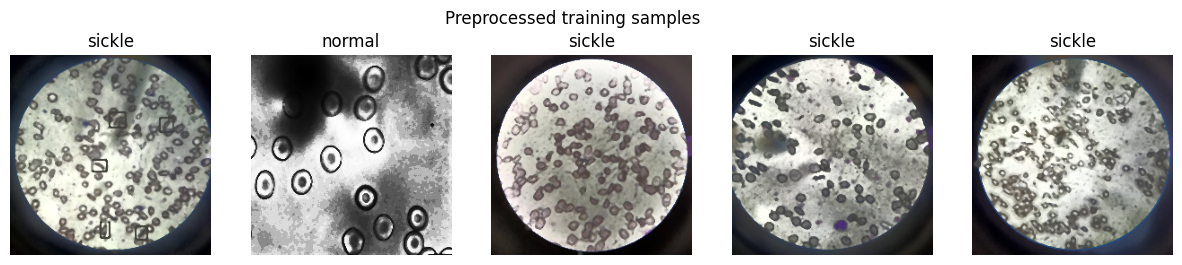

In [ ]:
# ================= SECTION 4: PREPROCESSING & PIPELINES =================
def preprocess_image(path):
    """OptiSCDNet-style enhancement: denoise + luminance normalization."""
    img = cv2.imread(str(path))
    if img is None:
        raise ValueError(f"Could not read {path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    img = cv2.medianBlur(img, 3)                                # noise removal
    ycc = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)
    ycc[..., 0] = cv2.equalizeHist(ycc[..., 0])                 # luminance equalization
    return cv2.cvtColor(ycc, cv2.COLOR_YCrCb2RGB)               # uint8 RGB

# preprocess every image once, cache in memory
image_cache = {}
for p in tqdm(df.path, desc="Preprocessing images"):
    image_cache[p] = preprocess_image(p)

def build_arrays(frame):
    X = np.stack([image_cache[p] for p in frame.path]).astype(np.float32)  # 0-255
    y = frame.label.to_numpy(dtype=np.float32)[:, None]
    return X, y

Xtr, ytr = build_arrays(train_df)
Xva, yva = build_arrays(val_df)
Xte, yte = build_arrays(test_df)
print("Shapes:", Xtr.shape, Xva.shape, Xte.shape)

def make_ds(X, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(Xtr, ytr, training=True)
val_ds   = make_ds(Xva, yva)
test_ds  = make_ds(Xte, yte)

# quick visual check
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, i in zip(axes, np.random.choice(len(Xtr), 5, replace=False)):
    ax.imshow(Xtr[i].astype("uint8")); ax.set_title("sickle" if ytr[i] else "normal")
    ax.axis("off")
plt.suptitle("Preprocessed training samples"); plt.show()

## Section 5 — Hybrid Model Architecture
**Dual-branch feature-fusion design** (best of your two ensemble experiments):

- **Branch A — EfficientNet-B0** (ImageNet weights, frozen in phase 1): lightweight pretrained feature extractor → the *cost-effective* core (~4M params vs ~138M for VGG16).
- **Branch B — OptiSCDNet-style residual CNN**: 4 residual blocks with **separable convolutions + squeeze-and-excitation (SE) channel attention**, trained from scratch on the sickle-cell domain.
- **Fusion head**: concatenate 1280-d + 256-d embeddings → BatchNorm → Dense(256, swish) → Dropout(0.4) → Dense(64, swish) → sigmoid.
- **Online augmentation** (flip / ±15° rotation / 10% zoom) is baked into the model so it applies to training only.

In [ ]:
# ================= SECTION 5: BUILD THE HYBRID MODEL =================
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(15 / 360),
    layers.RandomZoom(0.1),
], name="augmentation")

# ---- OptiSCDNet-style residual block with SE attention ----
def optiscd_block(x, filters, stride=1, name="block"):
    shortcut = x
    x = layers.Conv2D(filters, 3, strides=stride, padding="same",
                      use_bias=False, name=f"{name}_conv")(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.Activation("swish", name=f"{name}_act1")(x)
    x = layers.SeparableConv2D(filters, 3, padding="same",
                               use_bias=False, name=f"{name}_sepconv")(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)

    # squeeze-and-excitation channel attention
    se = layers.GlobalAveragePooling2D(name=f"{name}_se_pool")(x)
    se = layers.Dense(max(filters // 8, 8), activation="swish", name=f"{name}_se_fc1")(se)
    se = layers.Dense(filters, activation="sigmoid", name=f"{name}_se_fc2")(se)
    se = layers.Reshape((1, 1, filters))(se)
    x = layers.Multiply()([x, se])

    if stride != 1 or int(shortcut.shape[-1]) != filters:
        shortcut = layers.Conv2D(filters, 1, strides=stride, padding="same",
                                 use_bias=False, name=f"{name}_shortcut")(shortcut)
        shortcut = layers.BatchNormalization(name=f"{name}_shortcut_bn")(shortcut)
    x = layers.Add()([x, shortcut])
    return layers.Activation("swish", name=f"{name}_out")(x)

def build_hybrid():
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), dtype=tf.float32, name="rgb_image")
    aug = augment(inputs)                       # online augmentation (training only)

    # ---- Branch A: pretrained EfficientNet-B0 (expects 0-255 input) ----
    eff_base = keras.applications.EfficientNetB0(
        include_top=False, weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3), name="efficientnetb0")
    eff_base.trainable = False
    eff = eff_base(aug, training=False)
    eff = layers.GlobalAveragePooling2D(name="eff_gap")(eff)          # 1280-d
    eff = layers.Dropout(0.25, name="eff_drop")(eff)

    # ---- Branch B: OptiSCDNet-style residual CNN ----
    custom = layers.Rescaling(1.0 / 255.0, name="rescale")(aug)
    custom = layers.Conv2D(32, 3, padding="same", use_bias=False, name="stem_conv")(custom)
    custom = layers.BatchNormalization(name="stem_bn")(custom)
    custom = layers.Activation("swish", name="stem_act")(custom)
    custom = layers.MaxPooling2D(2, name="stem_pool")(custom)
    custom = optiscd_block(custom, 32,  1, "opti_block1")
    custom = optiscd_block(custom, 64,  2, "opti_block2")
    custom = optiscd_block(custom, 128, 2, "opti_block3")
    custom = optiscd_block(custom, 192, 2, "opti_block4")
    custom = layers.GlobalAveragePooling2D(name="opti_gap")(custom)
    custom = layers.Dense(256, activation="swish", name="opti_dense")(custom)
    custom = layers.Dropout(0.30, name="opti_drop")(custom)

    # ---- Feature fusion head ----
    fused = layers.Concatenate(name="feature_fusion")([eff, custom])   # 1536-d
    fused = layers.BatchNormalization(name="fusion_bn")(fused)
    fused = layers.Dense(256, activation="swish", name="fusion_dense1")(fused)
    fused = layers.Dropout(0.40, name="fusion_drop1")(fused)
    fused = layers.Dense(64, activation="swish", name="fusion_dense2")(fused)
    outputs = layers.Dense(1, activation="sigmoid", name="positive_probability")(fused)

    return keras.Model(inputs, outputs, name="Hybrid_SCD_Model"), eff_base

model, eff_base = build_hybrid()
model.summary()
print(f"Total parameters: {model.count_params():,}")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "Hybrid_SCD_Model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ rgb_image           │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 224, 224,  │          0 │ rgb_image[0][0]   │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescale (Rescaling) │ (None, 224, 224,  │          0 │ augmentation[0][… │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 224, 224,  │        864 │ rescale[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 224, 224,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_act            │ (None, 224, 224,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_pool           │ (None, 112, 112,  │          0 │ stem_act[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ opti_block1_conv    │ (None, 112, 112,  │      9,216 │ stem_pool[0][0]   │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ opti_block1_bn1     │ (None, 112, 112,  │        128 │ opti_block1_conv… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ opti_block1_act1    │ (None, 112, 112,  │          0 │ opti_block1_bn1[… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ opti_block1_sepconv │ (None, 112, 112,  │      1,312 │ opti_block1_act1… │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ opti_block1_bn2     │ (None, 112, 112,  │        128 │ opti_block1_sepc… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ opti_block1_se_pool │ (None, 32)        │          0 │ opti_block1_bn2[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ opti_block1_se_fc1  │ (None, 8)         │        264 │ opti_block1_se_p… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ opti_block1_se_fc2  │ (None, 32)        │        288 │ opti_block1_se_f… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 32)  │          0 │ opti_block1_se_f… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 112, 112,  │          0 │ opti_block1_bn2[… │
│                     │ 32)               │            │ reshape[0][0]   

 Total params: 4,955,772 (18.90 MB)

 Trainable params: 900,633 (3.44 MB)

 Non-trainable params: 4,055,139 (15.47 MB)

Total parameters: 4,955,772


## Section 6 — Class Weights, Compilation & Callbacks
- **Balanced class weights** computed from the training split only (handles the negative/positive imbalance).
- Callbacks (from your ensemble experiments): `ModelCheckpoint` on **val-AUC**, `EarlyStopping` with best-weight restore, `ReduceLROnPlateau`, `CSVLogger`.

In [ ]:
# ============ SECTION 6: CLASS WEIGHTS, COMPILE, CALLBACKS ============
ytr_flat = ytr.ravel().astype(int)
counts = np.bincount(ytr_flat)
n_train = len(ytr_flat)
CLASS_WEIGHT = {0: n_train / (2.0 * counts[0]),
                1: n_train / (2.0 * counts[1])}
print("Training class counts:", dict(enumerate(counts)))
print("Class weights:", CLASS_WEIGHT)

BEST_MODEL_PATH = OUTPUT_DIR / "best_hybrid.keras"

def compile_model(lr):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=[keras.metrics.BinaryAccuracy(name="accuracy"),
                 keras.metrics.Precision(name="precision"),
                 keras.metrics.Recall(name="recall"),
                 keras.metrics.AUC(name="auc")])

def make_callbacks(phase):
    return [
        keras.callbacks.ModelCheckpoint(str(BEST_MODEL_PATH), monitor="val_auc",
                                        mode="max", save_best_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                          patience=2, min_lr=1e-7, verbose=1),
        keras.callbacks.CSVLogger(str(OUTPUT_DIR / f"training_{phase}.csv"))]

Training class counts: {0: np.int64(128), 1: np.int64(607)}
Class weights: {0: np.float64(2.87109375), 1: np.float64(0.6054365733113674)}


## Section 7 — Phase 1: Train Head + OptiSCD Branch (EfficientNet Frozen)
Fast feature-extraction phase: only the new branch and the fusion head learn.

In [ ]:
# ================= SECTION 7: PHASE 1 TRAINING =================
compile_model(PHASE1_LR)
print("PHASE 1 — EfficientNet-B0 frozen, training custom branch + fusion head")
history1 = model.fit(train_ds, validation_data=val_ds,
                     epochs=PHASE1_EPOCHS,
                     class_weight=CLASS_WEIGHT,
                     callbacks=make_callbacks("phase1"))

PHASE 1 — EfficientNet-B0 frozen, training custom branch + fusion head
Epoch 1/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.7320 - auc: 0.7543 - loss: 0.6482 - precision: 0.9150 - recall: 0.7424
Epoch 1: val_auc improved from None to 0.95776, saving model to /content/drive/MyDrive/Final_Hybrid_Model_Results/best_hybrid.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Final_Hybrid_Model_Results/best_hybrid.keras
46/46 ━━━━━━━━━━━━━━━━━━━━ 40s 311ms/step - accuracy: 0.7891 - auc: 0.8624 - loss: 0.5254 - precision: 0.9431 - recall: 0.7924 - val_accuracy: 0.9006 - val_auc: 0.9578 - val_loss: 0.3304 - val_precision: 0.9675 - val_recall: 0.9084 - learning_rate: 0.0010
Epoch 2/15
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step - accuracy: 0.8387 - auc: 0.9129 - loss: 0.4243 - precision: 0.9389 - recall: 0.8565
Epoch 2: val_auc did not improve from 0.95776
46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 168ms/step - accuracy: 0.8381 - auc: 0.9134 - loss: 0.3994 - precision: 0.9604 - recall:

## Section 8 — Phase 2: Fine-Tune Top EfficientNet-B0 Layers
Unfreezes the **last 40 backbone layers** (BatchNorm stays frozen for stable statistics) and trains everything with a small learning rate.

In [ ]:
# ================= SECTION 8: PHASE 2 FINE-TUNING =================
print("PHASE 2 — fine-tuning last 40 EfficientNet-B0 layers")
eff_base.trainable = True
for layer in eff_base.layers[:-40]:
    layer.trainable = False
for layer in eff_base.layers:                      # keep BatchNorm frozen
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
print("Trainable backbone layers:",
      sum(int(l.trainable) for l in eff_base.layers), "of", len(eff_base.layers))

compile_model(PHASE2_LR)                            # recompile after flag change!
history2 = model.fit(train_ds, validation_data=val_ds,
                     epochs=PHASE2_EPOCHS,
                     class_weight=CLASS_WEIGHT,
                     callbacks=make_callbacks("phase2"))

# load the checkpoint with the best validation AUC
model = keras.models.load_model(BEST_MODEL_PATH)
model.save(OUTPUT_DIR / "final_hybrid_model.keras")
print("Saved:", OUTPUT_DIR / "final_hybrid_model.keras")

PHASE 2 — fine-tuning last 40 EfficientNet-B0 layers
Trainable backbone layers: 32 of 238
Epoch 1/40
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.8870 - auc: 0.9058 - loss: 0.3425 - precision: 0.9587 - recall: 0.9045
Epoch 1: val_auc improved from None to 0.95445, saving model to /content/drive/MyDrive/Final_Hybrid_Model_Results/best_hybrid.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Final_Hybrid_Model_Results/best_hybrid.keras
46/46 ━━━━━━━━━━━━━━━━━━━━ 36s 295ms/step - accuracy: 0.8884 - auc: 0.9227 - loss: 0.3752 - precision: 0.9581 - recall: 0.9044 - val_accuracy: 0.9006 - val_auc: 0.9545 - val_loss: 0.3068 - val_precision: 0.9675 - val_recall: 0.9084 - learning_rate: 2.0000e-05
Epoch 2/40
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - accuracy: 0.8701 - auc: 0.9080 - loss: 0.4392 - precision: 0.9537 - recall: 0.8836
Epoch 2: val_auc did not improve from 0.95445
46/46 ━━━━━━━━━━━━━━━━━━━━ 8s 179ms/step - accuracy: 0.8735 - auc: 0.9222 - loss: 0.3696 - prec

## Section 9 — Training History Curves

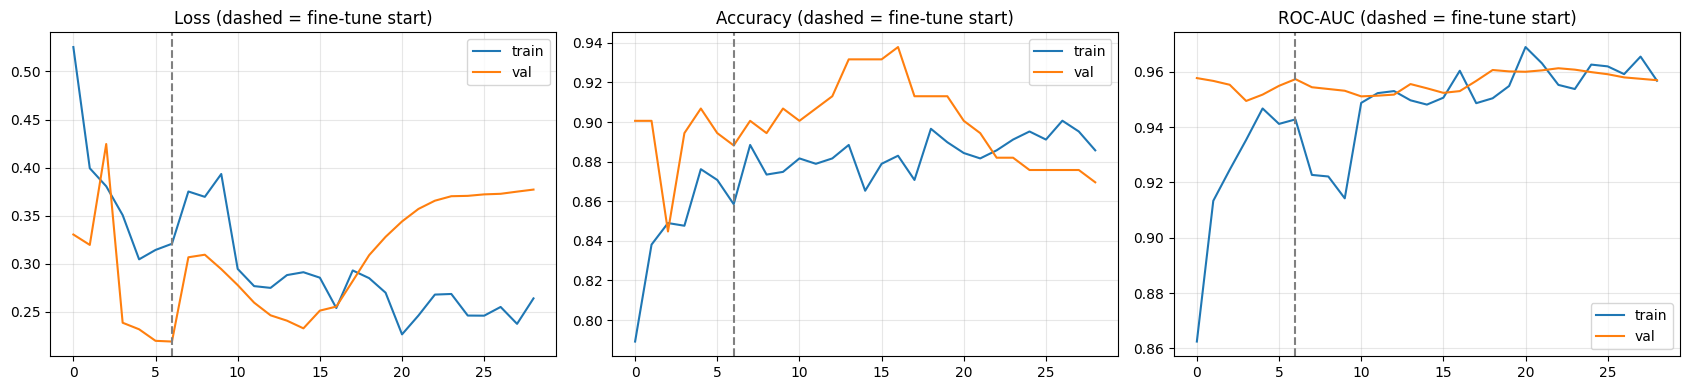

In [ ]:
# ================= SECTION 9: TRAINING HISTORY =================
hist = {k: history1.history[k] + history2.history[k] for k in history1.history}
split_at = len(history1.history["loss"])

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, metric, title in zip(ax,
        ["loss", "accuracy", "auc"],
        ["Loss", "Accuracy", "ROC-AUC"]):
    a.plot(hist[metric], label="train")
    a.plot(hist[f"val_{metric}"], label="val")
    a.axvline(split_at - 1, ls="--", c="gray")
    a.set_title(f"{title} (dashed = fine-tune start)"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=300)
plt.show()

## Section 10 — Held-Out Test Evaluation
Full metric suite on the unseen test set: Accuracy, Precision, Recall/Sensitivity, Specificity, F1, ROC-AUC, PR-AUC + confusion matrix + classification report.

10/10 ━━━━━━━━━━━━━━━━━━━━ 7s 437ms/step
=== FINAL HYBRID MODEL — HELD-OUT TEST RESULTS ===
test_images           156.000000
threshold               0.500000
accuracy                0.852564
precision               0.957265
sensitivity_recall      0.861538
specificity             0.807692
f1_score                0.906883
roc_auc                 0.922189
pr_auc                  0.979461
tn                     21.000000
fp                      5.000000
fn                     18.000000
tp                    112.000000

Classification report:
              precision    recall  f1-score   support

    Negative      0.538     0.808     0.646        26
    Positive      0.957     0.862     0.907       130

    accuracy                          0.853       156
   macro avg      0.748     0.835     0.777       156
weighted avg      0.887     0.853     0.863       156



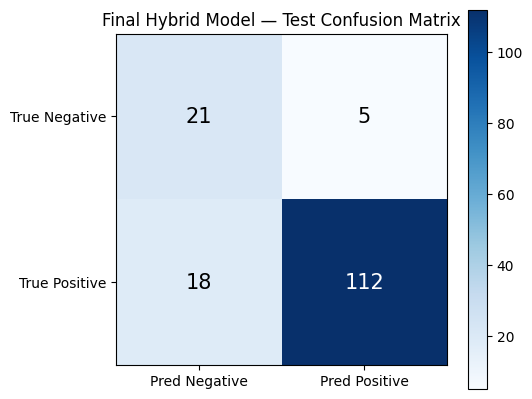

In [ ]:
# ================= SECTION 10: TEST EVALUATION =================
y_scores = model.predict(test_ds, verbose=1).reshape(-1)
y_true   = yte.ravel().astype(int)
y_pred   = (y_scores >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
metrics = {
    "test_images": int(len(y_true)),
    "threshold": 0.5,
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "precision": float(precision_score(y_true, y_pred, zero_division=0)),
    "sensitivity_recall": float(recall_score(y_true, y_pred, zero_division=0)),
    "specificity": float(tn / (tn + fp)) if (tn + fp) else 0.0,
    "f1_score": float(f1_score(y_true, y_pred, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_true, y_scores)),
    "pr_auc": float(average_precision_score(y_true, y_scores)),
    "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

print("=== FINAL HYBRID MODEL — HELD-OUT TEST RESULTS ===")
print(pd.Series(metrics).to_string())
print("\nClassification report:")
print(classification_report(y_true, y_pred, labels=[0, 1],
                            target_names=["Negative", "Positive"],
                            zero_division=0, digits=3))
json.dump(metrics, open(OUTPUT_DIR / "test_metrics.json", "w"), indent=2)

# confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], ["Pred Negative", "Pred Positive"])
ax.set_yticks([0, 1], ["True Negative", "True Positive"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=15,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_title("Final Hybrid Model — Test Confusion Matrix")
fig.colorbar(im); plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=300)
plt.show()

# save per-image predictions
pred_df = test_df.copy()
pred_df["positive_probability"] = y_scores
pred_df["predicted_label"] = y_pred
pred_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

## Section 11 — ROC & Precision-Recall Curves

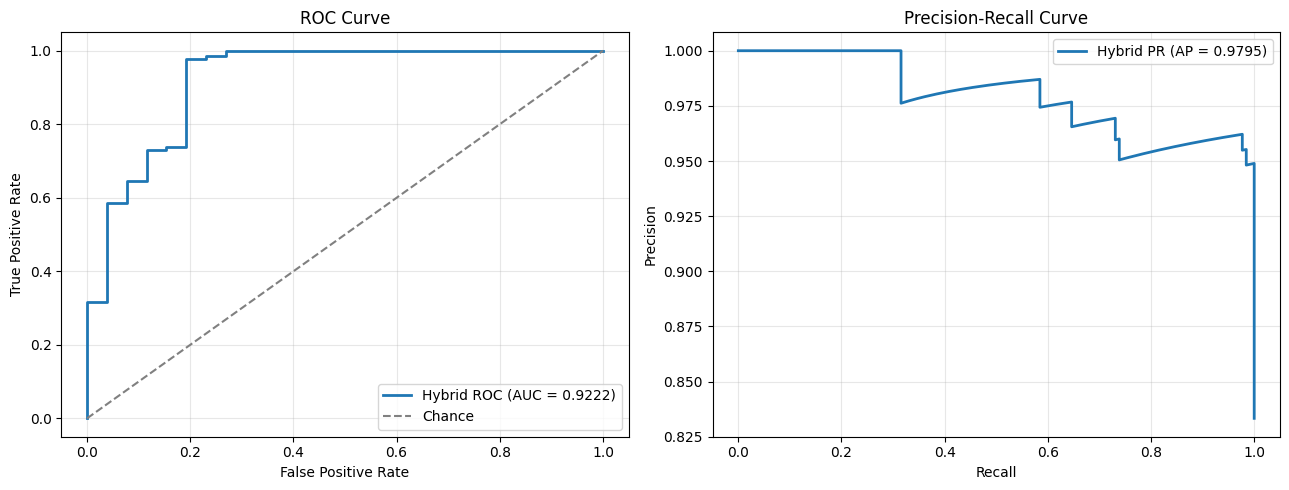

In [ ]:
# ================= SECTION 11: ROC & PR CURVES =================
fpr, tpr, _ = roc_curve(y_true, y_scores)
prec, rec, _ = precision_recall_curve(y_true, y_scores)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot(fpr, tpr, lw=2, label=f"Hybrid ROC (AUC = {metrics['roc_auc']:.4f})")
ax[0].plot([0, 1], [0, 1], "--", c="gray", label="Chance")
ax[0].set_xlabel("False Positive Rate"); ax[0].set_ylabel("True Positive Rate")
ax[0].set_title("ROC Curve"); ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(rec, prec, lw=2, label=f"Hybrid PR (AP = {metrics['pr_auc']:.4f})")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-Recall Curve"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_pr_curves.png", dpi=300)
plt.show()

## Section 12 — Subgroup Analysis per Source Folder
Checks whether performance holds for `positive_labelled` vs `positive_unlabelled` images separately.

In [ ]:
# ================= SECTION 12: SUBGROUP ANALYSIS =================
rows = []
for folder in CLASS_FOLDERS:
    sub = pred_df[pred_df.folder == folder]
    if sub.empty:
        continue
    yt = sub.label.to_numpy(int); yp = sub.predicted_label.to_numpy(int)
    ys = sub.positive_probability.to_numpy(float)
    rows.append({"folder": folder, "images": len(sub),
                 "accuracy": accuracy_score(yt, yp),
                 "precision": precision_score(yt, yp, zero_division=0),
                 "recall": recall_score(yt, yp, zero_division=0),
                 "f1": f1_score(yt, yp, zero_division=0),
                 "roc_auc": roc_auc_score(yt, ys) if len(np.unique(yt)) == 2 else np.nan})
subgroup_df = pd.DataFrame(rows)
print(subgroup_df.to_string(index=False))
subgroup_df.to_csv(OUTPUT_DIR / "subgroup_metrics.csv", index=False)

             folder  images  accuracy  precision   recall       f1  roc_auc
           negative      26  0.807692        0.0 0.000000 0.000000      NaN
positive_unlabelled      60  0.783333        1.0 0.783333 0.878505      NaN
  positive_labelled      70  0.928571        1.0 0.928571 0.962963      NaN


## Section 13 — Cost-Effectiveness Analysis (Key for the Project Title)
Quantifies why this model is **cost-effective**: parameter count, model size on disk, and mean inference time per image (averaged over 100 runs), compared against the other backbones you experimented with.

Total parameters : 4,955,772
Model size       : 44.5 MB
Mean inference   : 398.4 ms/image

                      Model  Approx. parameters  Inference ms/img                                  Notes
            VGG16 (single)           138357544               NaN                      heaviest baseline
      InceptionV3 (single)            23851784               NaN                          299x299 input
      DenseNet121 (single)             8062504               NaN                                   None
  EfficientNet-B0 (single)             5330571               NaN                           your Model 6
DenseNet121+VGG16 ensemble           146420048               NaN                      heaviest ensemble
 FINAL HYBRID (this model)             4955772             398.4 EffNet-B0 + OptiSCD residual-SE branch


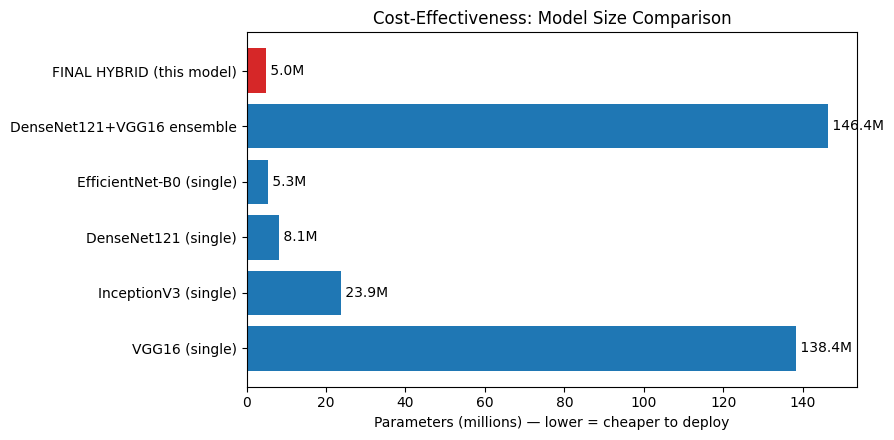

In [ ]:
# ================= SECTION 13: COST-EFFECTIVENESS =================
# --- parameter count & model size ---
total_params = model.count_params()
model_size_mb = os.path.getsize(OUTPUT_DIR / "final_hybrid_model.keras") / 1e6

# --- mean single-image inference time (100 runs after 10 warm-ups) ---
x1 = Xte[:1]
for _ in range(10):
    model(x1, training=False)
t0 = time.perf_counter()
for _ in range(100):
    model(x1, training=False)
inference_ms = (time.perf_counter() - t0) / 100 * 1000

print(f"Total parameters : {total_params:,}")
print(f"Model size       : {model_size_mb:.1f} MB")
print(f"Mean inference   : {inference_ms:.1f} ms/image")

# --- comparison with the other models from this project (published backbone sizes) ---
comparison = pd.DataFrame([
    ["VGG16 (single)",              138_357_544, None, "heaviest baseline"],
    ["InceptionV3 (single)",         23_851_784, None, "299x299 input"],
    ["DenseNet121 (single)",          8_062_504, None, None],
    ["EfficientNet-B0 (single)",      5_330_571, None, "your Model 6"],
    ["DenseNet121+VGG16 ensemble",  146_420_048, None, "heaviest ensemble"],
    ["FINAL HYBRID (this model)",   int(total_params), round(inference_ms, 1),
     "EffNet-B0 + OptiSCD residual-SE branch"],
], columns=["Model", "Approx. parameters", "Inference ms/img", "Notes"])
print("\n", comparison.to_string(index=False))
comparison.to_csv(OUTPUT_DIR / "cost_effectiveness_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(comparison.Model, comparison["Approx. parameters"] / 1e6,
        color=["#d62728" if "FINAL" in m else "#1f77b4" for m in comparison.Model])
ax.set_xlabel("Parameters (millions) — lower = cheaper to deploy")
ax.set_title("Cost-Effectiveness: Model Size Comparison")
for i, v in enumerate(comparison["Approx. parameters"] / 1e6):
    ax.text(v, i, f" {v:.1f}M", va="center")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cost_effectiveness.png", dpi=300)
plt.show()

## Section 14 — Grad-CAM Interpretability
Visual explanations on test images — shows which blood-smear regions drive the prediction (strong material for the final review).

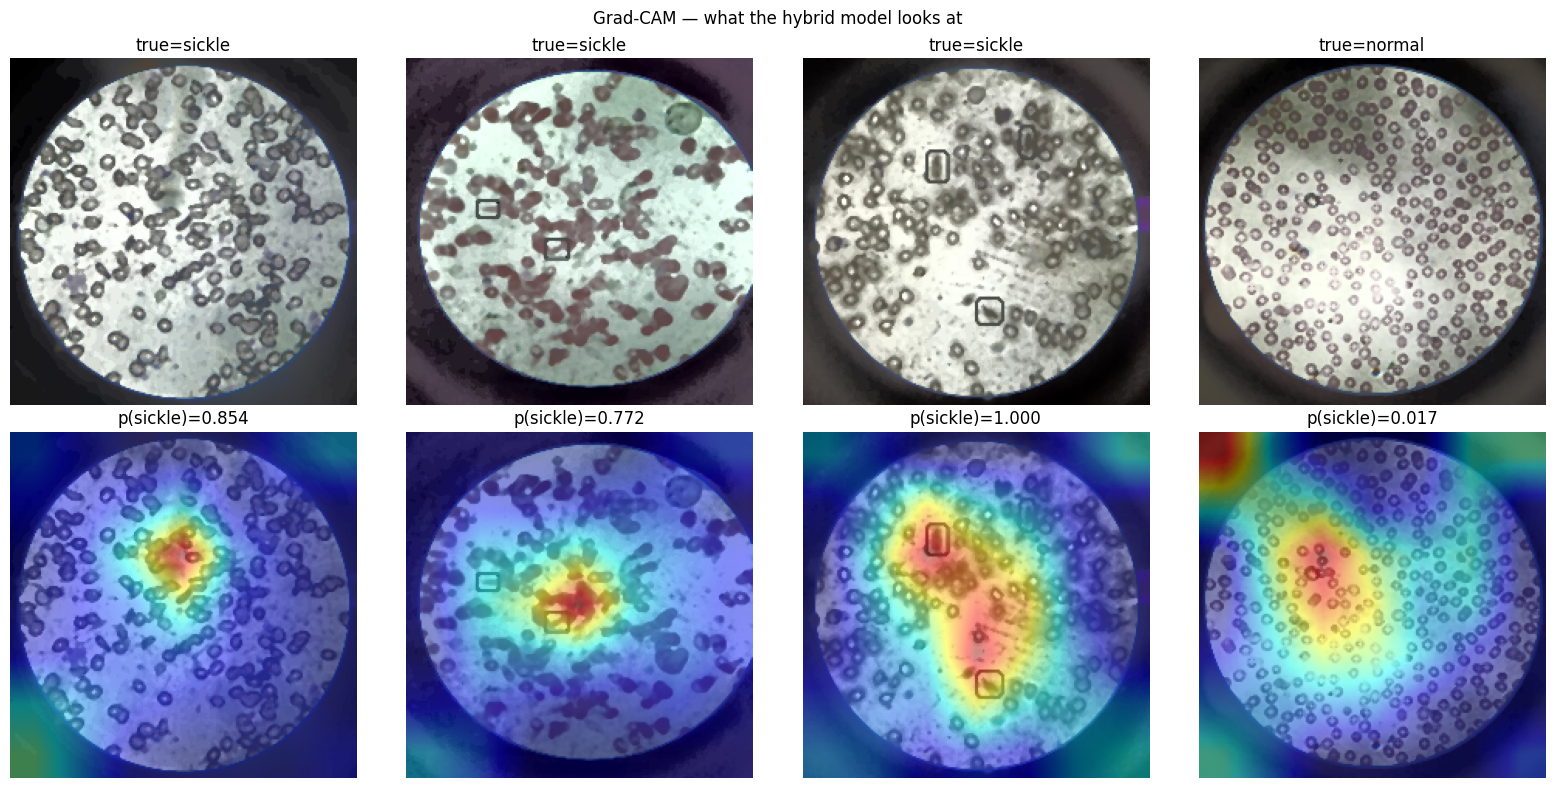

In [ ]:
# ================= SECTION 14: GRAD-CAM =================
# Build the Grad-CAM model using the sub-model 'efficientnetb0' to avoid duplicate name conflicts
eff_model = model.get_layer("efficientnetb0")
last_conv = eff_model.get_layer("top_activation")
grad_model = keras.Model(eff_model.input, [last_conv.output, eff_model.output])

def make_gradcam(img_array):
    img = img_array[None].astype(np.float32)

    # Get the final prediction probability from the main model
    preds_main = model(img, training=False)
    prob = float(preds_main[0, 0])

    # Extract gradients and activations from the sub-model
    with tf.GradientTape() as tape:
        conv_out, eff_out = grad_model(img, training=False)
        # We can use the sum of the feature maps as a proxy loss for the target class
        loss = tf.reduce_mean(eff_out)

    grads = tape.gradient(loss, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2))               # GAP of gradients
    cam = tf.reduce_sum(conv_out * weights[:, None, None, :], axis=-1)[0]
    cam = tf.maximum(cam, 0) / (tf.reduce_max(cam) + 1e-8)
    cam = cv2.resize(cam.numpy(), (IMG_SIZE, IMG_SIZE))
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay = np.uint8(0.55 * img_array + 0.45 * heatmap)
    return overlay, prob

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for k, ax_col in enumerate(axes.T):
    i = np.random.randint(len(Xte))
    overlay, prob = make_gradcam(Xte[i])
    ax_col[0].imshow(Xte[i].astype("uint8")); ax_col[0].axis("off")
    ax_col[0].set_title(f"true={'sickle' if y_true[i] else 'normal'}")
    ax_col[1].imshow(overlay); ax_col[1].axis("off")
    ax_col[1].set_title(f"p(sickle)={prob:.3f}")
axes[0, 0].set_ylabel("Original"); axes[1, 0].set_ylabel("Grad-CAM")
plt.suptitle("Grad-CAM — what the hybrid model looks at")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "gradcam_examples.png", dpi=300)
plt.show()

## Section 15 — Save Artifacts & Single-Image Prediction Demo
Saves the run configuration and provides a reusable `predict_image()` function for new blood-smear images.

All artifacts saved to: /content/drive/MyDrive/Final_Hybrid_Model_Results
['train_manifest.csv', 'val_manifest.csv', 'test_manifest.csv', 'training_phase1.csv', 'best_hybrid.keras', 'training_phase2.csv', 'final_hybrid_model.keras', 'training_curves.png', 'test_metrics.json', 'confusion_matrix.png', 'test_predictions.csv', 'roc_pr_curves.png', 'subgroup_metrics.csv', 'cost_effectiveness_comparison.csv', 'cost_effectiveness.png', 'gradcam_examples.png', 'run_config.json']


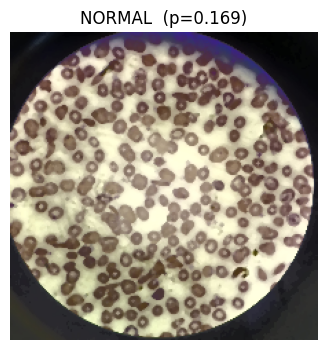

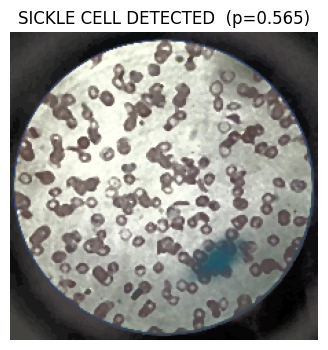

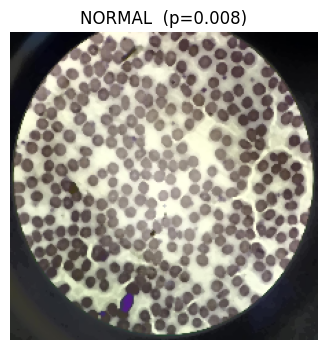

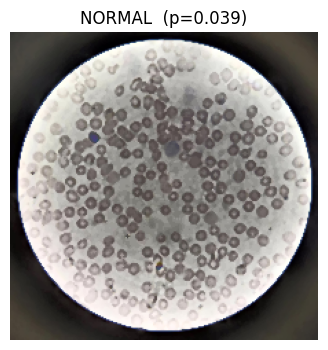

In [ ]:
# ================= SECTION 15: SAVE CONFIG + PREDICTION DEMO =================
config = {
    "project": "Hybrid Model For Cost Effective Sickle Cell Anemia Detection",
    "architecture": "EfficientNet-B0 (ImageNet) + OptiSCDNet-style residual-SE CNN, feature-fusion head",
    "preprocessing": "BGR>RGB, 224x224 INTER_AREA, median blur k=3, YCrCb Y-channel histogram equalization",
    "split": "SHA-256 group-stratified 70/15/15 (no duplicate leakage)",
    "training": f"Two-phase: frozen backbone {PHASE1_EPOCHS}ep @ {PHASE1_LR}, "
                f"fine-tune last 40 layers {PHASE2_EPOCHS}ep @ {PHASE2_LR}",
    "class_weight": {str(k): round(v, 4) for k, v in CLASS_WEIGHT.items()},
    "test_metrics": metrics,
    "params": int(total_params),
    "inference_ms": round(inference_ms, 1)}
json.dump(config, open(OUTPUT_DIR / "run_config.json", "w"), indent=2)
print("All artifacts saved to:", OUTPUT_DIR)
print(os.listdir(OUTPUT_DIR))

def predict_image(path):
    """Predict a new blood-smear image with the same preprocessing."""
    img = preprocess_image(path)
    prob = float(model.predict(img[None].astype(np.float32), verbose=0)[0, 0])
    plt.figure(figsize=(4, 4))
    plt.imshow(img); plt.axis("off")
    plt.title(f"{'SICKLE CELL DETECTED' if prob >= 0.5 else 'NORMAL'}  (p={prob:.3f})")
    plt.show()
    return prob

# --- demo on a few test images (change paths to any new image) ---
demo = pd.concat([pred_df[pred_df.label == 1].head(2),
                  pred_df[pred_df.label == 0].head(2)])
for p in demo.path:
    predict_image(p)